# Phase 5 — Designing the experiment

Phase 4 estimated, from historical data, that per-order model promises would cut late deliveries by about a
quarter. Two of its links cannot be verified without changing what customers see:

1. **Reviews:** do reviews respond to the new promises the way the Phase 2 dose-response predicts?
2. **Sales:** what is a shorter promise worth? The data only contains orders that were placed, so the
   customers a long promise turned away never appear.

This notebook sizes an experiment that answers both, using the real data wherever possible:
closed-form power, **A/A tests** on real orders, a **replay** of real deliveries against each arm's
promise, and a **simulated geo experiment** on real regional order volumes. The resulting plan is in
[`docs/PHASE5_EXPERIMENT_PLAN.md`](../docs/PHASE5_EXPERIMENT_PLAN.md).

In [1]:
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT / "analysis"))
import experiment as E  # noqa: E402
import policy as Y  # noqa: E402
import predict as P  # noqa: E402

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
DB = str(ROOT / "warehouse" / "olist.duckdb")
FIG = ROOT / "docs" / "figures"

BLUE, ORANGE, AQUA, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Design in one table

| | |
|---|---|
| **Arms** | **Control**: Olist's current promise · **Reliable**: model P92.5 (Phase 4 option C) · **Fast**: the model quantile that matches today's late rate with shorter promises (Phase 4 option B) |
| **Unit** | customer (all of a customer's visits and orders see the same arm), stratified by destination state |
| **What changes** | only the promised date shown at checkout; logistics, sellers and the review survey are untouched |
| **Primary metrics** | 1-star review rate per delivered order (Reliable vs Control); orders per visitor (Fast vs Control) |
| **Secondary** | late-delivery rate, mean review score, average promise shown |
| **Guardrails** | late rate (Fast must not exceed Control by > 1 pt), cancellation rate, review response rate, sample-ratio mismatch |
| **Long-term** | 180-day repeat purchase, from a 10% holdout kept for 12 months |

## 2. Inputs from the data

In [2]:
con = duckdb.connect(DB, read_only=True)
monthly = con.execute("""
    select date_trunc('month', purchase_date) as month,
           count(*) as orders,
           count(distinct customer_unique_id) filter (where session_number = 1) as new_customers
    from marts.fct_orders
    where purchase_date between '2018-01-01' and '2018-08-31' and order_status <> 'canceled'
    group by 1 order by 1
""").df()
orders_per_month = monthly.orders.mean()
new_customers_per_month = monthly.new_customers.mean()

preds = pd.read_parquet(ROOT / "warehouse" / "phase3_predictions.parquet")
test = preds[preds.split == "test"].reset_index(drop=True)
facts = con.execute("""
    select order_id, customer_unique_id, review_score, has_review from marts.fct_orders
""").df()
test = test.merge(facts, on="order_id", how="left")
opts = pd.read_csv(ROOT / "docs" / "phase4_options.csv", index_col=0)

print(f"orders per month (2018): {orders_per_month:,.0f}   new customers per month: {new_customers_per_month:,.0f}")
opts[["late rate", "avg promise (days)", "review effect (stars)", "1-star rate effect"]]

orders per month (2018): 6,710   new customers per month: 6,473


,late rate,avg promise (days),review effect (stars),1-star rate effect
option,,,,
Olist today,0.090,22.912,-0.009,0.026
"A. fewer late, same avg promise",0.069,22.911,0.037,0.015
"B. shorter promises, same late rate",0.091,20.784,-0.032,0.027
"C. deployable (P92.5, chosen in Jan)",0.065,23.527,0.053,0.012


## 3. How many orders does each question need?

Expected effects come from Phase 4 (Reliable = option C, Fast = option B). Baselines are the Feb–Aug 2018
test period.

In [3]:
reviewed = test[test.has_review == True].copy()  # noqa: E712
reviewed["one_star"] = (reviewed.review_score == 1).astype(int)
p_one = reviewed.one_star.mean()
sd_review = reviewed.review_score.std()

ctrl, rel, fast = opts.iloc[0], opts.iloc[3], opts.iloc[2]
d_one = rel["1-star rate effect"] - ctrl["1-star rate effect"]
d_review = rel["review effect (stars)"] - ctrl["review effect (stars)"]

# Regression adjustment (CUPED): variance explained by pre-treatment covariates.
qs = reviewed[Y.QUANTILE_COLS].to_numpy()
reviewed["p_late_olist"] = P.prob_late(qs, reviewed.promised_days.to_numpy(float))
reviewed["log_q500"] = np.log1p(reviewed.q500)
reviewed["log_q900"] = np.log1p(reviewed.q900)
COVS = ["p_late_olist", "log_q500", "log_q900", "promised_days"]
r2 = {y: sm.OLS(reviewed[y].astype(float), sm.add_constant(reviewed[COVS])).fit().rsquared
      for y in ["one_star", "review_score"]}

rows = [
    {"question": "late rate falls (Reliable)", "baseline": ctrl["late rate"],
     "effect": rel["late rate"] - ctrl["late rate"],
     "orders per arm": E.n_per_arm_proportions(ctrl["late rate"], rel["late rate"])},
    {"question": "1-star rate falls (Reliable)", "baseline": p_one, "effect": d_one,
     "orders per arm": E.n_per_arm_proportions(p_one, p_one + d_one)},
    {"question": "1-star rate falls, CUPED", "baseline": p_one, "effect": d_one,
     "orders per arm": E.n_per_arm_proportions(p_one, p_one + d_one) * (1 - r2["one_star"])},
    {"question": "mean review rises (Reliable), CUPED", "baseline": reviewed.review_score.mean(), "effect": d_review,
     "orders per arm": E.n_per_arm_means(sd_review, d_review, r2=r2["review_score"])},
]
sizes = pd.DataFrame(rows).set_index("question")
# Reviews arrive for ~99% of delivered orders, a few weeks after purchase.
sizes["months (2 arms)"] = 2 * sizes["orders per arm"] / orders_per_month
sizes["months (3 arms)"] = 3 * sizes["orders per arm"] / orders_per_month
print(f"CUPED R^2: one_star {r2['one_star']:.3f}, review_score {r2['review_score']:.3f}")
sizes

CUPED R^2: one_star 0.018, review_score 0.025


,baseline,effect,orders per arm,months (2 arms),months (3 arms)
question,,,,,
late rate falls (Reliable),0.090,-0.025,"1,758.855",0.524,0.786
1-star rate falls (Reliable),0.109,-0.014,"7,262.579",2.165,3.247
"1-star rate falls, CUPED",0.109,-0.014,"7,128.930",2.125,3.188
"mean review rises (Reliable), CUPED",4.124,0.062,"6,898.408",2.056,3.084


The late-rate effect is large and shows up within weeks. The **1-star effect is the binding constraint**: it
needs about 7,000 reviewed orders per arm, which is roughly 2 months of this dataset's volume with two arms or 3 months
with three, plus 2–4 weeks for reviews to come in. Regression adjustment on checkout-time predictions explains
only about 2% of review variance, so it saves little time. That is an honest negative: reviews are noisy, and almost
none of that noise is predictable at checkout.

## 4. Does the analysis hold up on real data? A/A tests

Before trusting a power calculation, split real customers at random many times with no treatment and check
that the analysis flags a difference only about 5% of the time. Customers with several orders make orders
correlated, which is why standard errors are clustered by customer.

In [4]:
aa = E.aa_test(reviewed, "one_star", n_sims=200)
aa_cuped = E.aa_test(reviewed, "one_star", n_sims=200, covariates=COVS)
pd.DataFrame({
    "false-positive rate": [aa.significant.mean(), aa_cuped.significant.mean()],
    "mean reported SE": [aa.se.mean(), aa_cuped.se.mean()],
    "actual SD of estimates": [aa.estimate.std(), aa_cuped.estimate.std()],
}, index=["unadjusted", "CUPED"])

,false-positive rate,mean reported SE,actual SD of estimates
unadjusted,0.070,0.003,0.003
CUPED,0.060,0.003,0.003


Over 200 random splits the analysis flags a "difference" 6–7% of the time, within simulation noise of the
nominal 5% (±3 points at 200 runs). The reported standard errors match the actual spread of the estimates, so
the analysis is correctly calibrated on this data.

## 5. Replay: power for the late-rate effect without modelling assumptions

Only the promise changes between arms; the parcel arrives on the same day. So for any real order we know
exactly whether it would have been late under each arm's promise. Sampling real orders, randomising
customers, and scoring each arm against its own promise gives an assumption-free power curve.

In [5]:
cdf = Y.cdf_grid(test)
late_ctrl = Y.days_late(test.promised_days.to_numpy(float), test) > 0
late_rel = Y.days_late(Y.uniform_quantile(cdf, 0.925), test) > 0
replay = E.replay_power(test, late_ctrl, late_rel, [250, 500, 1000, 2000, 4000], n_sims=200)
replay

,orders,power
0,250,0.110
1,500,0.180
2,1000,0.330
3,2000,0.550
4,4000,0.875


About 4,000 orders in total (2,000 per arm) give 80%+ power to see the late-rate drop, in line with the
closed-form 1,760 per arm. That is two to three weeks of this dataset's volume. This metric works as an early **manipulation check**: if late rates do not
fall in the first weeks, something is wrong with the deployment.

## 6. Sales: why this needs visitor-level randomisation

The Fast arm exists to measure what shorter promises are worth in sales. Phase 4 borrowed an elasticity
(+0.73% sales per day of faster promise; Cui et al., 2024), which for option B's 2.1 days means about **+1.6%**.

**Option 1: geo experiment on order volume.** Randomise two-digit CEP regions (~100) and compare order
growth. Simulated on real weekly regional orders, with lifts injected into treated regions:

In [6]:
regions = con.execute("""
    select f.order_id, f.purchase_date, c.customer_zip_prefix // 1000 as region
    from marts.fct_orders f
    join staging.stg_olist__orders o using (order_id)
    join staging.stg_olist__customers c using (customer_id)
    where f.purchase_date between '2017-06-01' and '2018-08-26'
""").df()
weekly = E.weekly_region_orders(regions)
geo = pd.concat([E.geo_power(weekly, 8, w, [0.0, 0.02, 0.05, 0.10, 0.20], n_sims=300) for w in [4, 8, 12]])
geo_tab = geo.pivot(index="lift", columns="test_weeks", values="power")
geo_tab.columns = [f"{w} weeks" for w in geo_tab.columns]
print(f"regions: {weekly.shape[0]}, weeks of history: {weekly.shape[1]}")
geo_tab

regions: 98, weeks of history: 65


,4 weeks,8 weeks,12 weeks
lift,,,
0.000,0.040,0.040,0.043
0.020,0.043,0.090,0.100
0.050,0.163,0.237,0.240
0.100,0.497,0.677,0.710
0.200,0.963,0.997,1.000


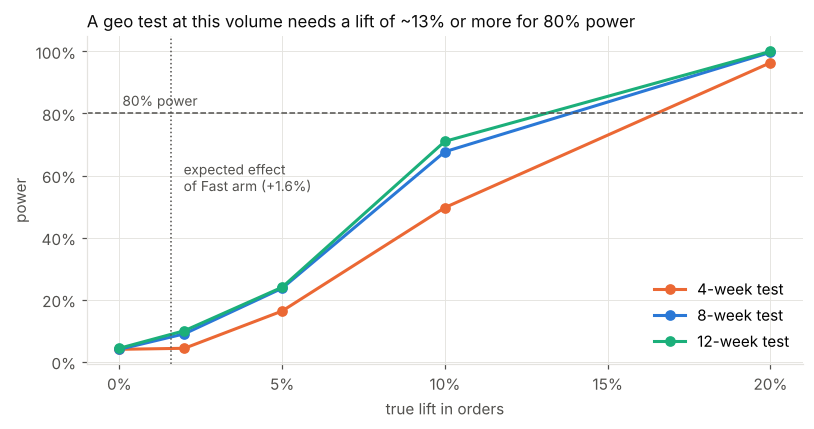

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for w, color in [(4, ORANGE), (8, BLUE), (12, AQUA)]:
    g = geo[geo.test_weeks == w]
    ax.plot(g.lift, g.power, color=color, lw=2, marker="o", ms=6, label=f"{w}-week test")
ax.axhline(0.8, color=INK2, lw=1, ls="--")
ax.axvline(0.016, color=INK2, lw=1, ls=":")
ax.annotate("expected effect\nof Fast arm (+1.6%)", (0.016, 0.55), xytext=(8, 0), textcoords="offset points",
            color=INK2, fontsize=9)
ax.annotate("80% power", (0.0, 0.8), xytext=(2, 5), textcoords="offset points", color=INK2, fontsize=9)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("true lift in orders")
ax.set_ylabel("power")
ax.set_title("A geo test at this volume needs a lift of ~13% or more for 80% power", loc="left", fontsize=11)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "05_geo_power.png", bbox_inches="tight")

Even a 12-week test needs a lift of about 13% for 80% power. Regional order volumes swing far more than a
1.6% effect, so a geo test is hopeless for this question at this
scale. False positives stay at about 4–5% (the 0% row), so the design is valid, just underpowered.

**Option 2 (recommended): visitor-level randomisation, conversion as the metric.** Each visitor sees one arm's
promise on the product page; the outcome is whether they buy. Visitor data is not in this dataset, so the
table below gives visitors per arm for a range of plausible baseline conversion rates:

In [8]:
rows = []
for base in [0.01, 0.02, 0.03, 0.05]:
    for lift in [0.016, 0.03, 0.05]:
        rows.append({"baseline conversion": base, "relative lift": lift,
                     "visitors per arm": E.n_per_arm_proportions(base, base * (1 + lift))})
conv = pd.DataFrame(rows).pivot(index="baseline conversion", columns="relative lift", values="visitors per arm")
conv.columns = [f"lift {c:.1%}" for c in conv.columns]
conv.map(lambda v: f"{v / 1e6:,.2f}M")

,lift 1.6%,lift 3.0%,lift 5.0%
baseline conversion,,,
0.010,6.12M,1.75M,0.64M
0.020,3.03M,0.87M,0.32M
0.030,2.00M,0.57M,0.21M
0.050,1.17M,0.34M,0.12M


Detecting a 1.6% relative lift needs **millions of visitors per arm**. That is routine for a large marketplace
but impossible for a small one. If traffic is limited, a more aggressive Fast arm (e.g. 5 days shorter, with a
larger expected lift) can be tested first, guarded by the late-rate stopping rule below.

## 7. Retention: a long-term holdout, not a test readout

Phase 2 found a plausible but unproven ~15% drop in 180-day repeat purchases after a late first order. To
measure retention directly:

In [9]:
p_rep = 0.020
for rel_drop in [0.15, 0.30]:
    n = E.n_per_arm_proportions(p_rep, p_rep * (1 - rel_drop))
    print(f"detect a {rel_drop:.0%} drop in repeat rate: {n:,.0f} new customers per arm "
          f"= {2 * n / new_customers_per_month:,.1f} months of new customers, then 6 months of follow-up")

detect a 15% drop in repeat rate: 31,667 new customers per arm = 9.8 months of new customers, then 6 months of follow-up
detect a 30% drop in repeat rate: 7,283 new customers per arm = 2.3 months of new customers, then 6 months of follow-up


Retention cannot be part of the launch decision at this volume. Instead, keep a **10% holdout** on the old
promises for 12 months after launch and read retention at the end.

## 8. Stopping rules

The Fast arm deliberately shortens promises, so lateness must be watched as the test runs. Four weekly looks
use O'Brien–Fleming boundaries on the late-rate difference (two-sided 5% overall):

In [10]:
looks = 4
c = 2.024  # O'Brien-Fleming constant for 4 equally spaced looks, two-sided alpha = 0.05
pd.DataFrame({"look": range(1, looks + 1),
              "share of data": [k / looks for k in range(1, looks + 1)],
              "stop if |z| exceeds": [c * np.sqrt(looks / k) for k in range(1, looks + 1)]}).set_index("look")

,share of data,stop if |z| exceeds
look,,
1,0.250,4.048
2,0.500,2.862
3,0.750,2.337
4,1.000,2.024


Early looks require overwhelming evidence (|z| > 4), so random early swings don't stop a good arm, while a
genuinely harmful one is caught quickly. A **sample-ratio mismatch** check (χ² on assignment counts) runs at
every look; any mismatch pauses the test until the assignment bug is found.

## 9. Plan summary

| Question | Arms | Sample needed | Time at this dataset's volume |
|---|---|---|---|
| Does Reliable cut late deliveries? (manipulation check) | Reliable vs Control | ~1,800–2,000 orders per arm | 2–4 weeks |
| Does Reliable cut 1-star reviews? (primary) | Reliable vs Control | ~7,000 reviewed orders per arm | ~2 months with 2 arms, ~3 months with 3, + review lag |
| Does Fast raise sales? (primary) | Fast vs Control | millions of visitors per arm for +1.6% | needs visitor-level traffic; geo test cannot do it |
| Does lateness cost repeat customers? | 10% holdout | ~32,000 new customers per arm for −15% | ~10 months of new customers + 6 months follow-up |

**Decision rule**
* **Ship Reliable** if the 1-star rate falls significantly and orders per visitor are not worse by more than
  1% (non-inferiority).
* **Ship Fast** only if conversion rises significantly and the late rate stays within 1 point of Control.

In [11]:
sizes.to_csv(ROOT / "docs" / "phase5_sample_sizes.csv")
geo.to_csv(ROOT / "docs" / "phase5_geo_power.csv", index=False)